## Setup Libraries

In [27]:
!pip install -q pytabkit

In [28]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [29]:
try:
    import xgboost
except:
    !pip install -q xgboost
    import xgboost

try:
    import lightgbm
except:
    !pip install -q lightgbm
    import lightgbm

try:
    import catboost
except:
    !pip install -q catboost
    import catboost

In [30]:
import random
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from importlib.metadata import version
from time import time

from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import KBinsDiscretizer, TargetEncoder
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

import torch
import pytabkit
from pytabkit import XGB_TD_Classifier, LGBM_TD_Classifier, CatBoost_TD_Classifier

warnings.filterwarnings('ignore')
print("PyTorch  version:", torch.__version__)
print("PyTabKit version:", version("pytabkit"))

def seed_everything(seed: int):
    print(f"🌱 Seeding everything with {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

PyTorch  version: 2.11.0+cu130
PyTabKit version: 1.8.0
🌱 Seeding everything with 42


In [31]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})

## Load Data

In [32]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

## =================================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


is_new_merchant                      2
is_fraud                             2
is_ai_generated_scam_attempt         2
billing_shipping_mismatch            2
ip_country_mismatch                  2
used_vpn                             2
is_foreign_transaction               2
cvv_retry_count                      4
auth_method                          5
prior_disputes                       5
card_type                            5
channel                              5
day_of_week                          7
device_type                          8
txn_count_last_24h                  12
merchant_category                   12
time_of_day_hour                    24
card_age_months                     49
customer_age                        64
velocity_score                     666
merchant_risk_score                950
hours_since_last_txn              3633
distance_from_home_km             4365
amount_usd                       13387
account_balance_usd              43317
id                       

## Preprocess Features

In [33]:
%%time
## NB: Original feature engineering

ID = 'id'
TARGET = 'is_fraud'

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

del train, test
print('-'*40)
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'bool']).columns.tolist()
print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
def feature_engineering(df, fit=False):
    # Categorize numericals
    for col in num_cols:
        cat_name = f"{col}_cat_"
        if fit:
            codes, uniques = np.floor(df[col]).factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = np.floor(df[col]).map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols

X, new_cat_cols, new_num_cols = feature_engineering(X, fit=True)
X_test, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols
print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape, "\n")
print('-'*40)

----------------------------------------
X      init shape: (699960, 24)
X_test init shape: (299984, 24) 

init len(cat_cols): 11
init len(num_cols): 13 

len(new_cat_cols): 13
len(new_num_cols): 0 

prep len(cat_cols): 24
prep len(num_cols): 13 

X      prep shape: (699960, 37)
X_test prep shape: (299984, 37) 

----------------------------------------
CPU times: user 421 ms, sys: 8.06 ms, total: 429 ms
Wall time: 426 ms


In [34]:
float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

In [35]:
FEATURES = [c for c in X.columns if c not in [ID, TARGET]]
combined = pd.concat([X, X_test], ignore_index=True)

digit_cols = []

for col in num_cols:
    scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
    for k in range(-2, 3):
        dig_col = f"{col}_DIGIT_{k}"
        combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int8').astype('category')
        digit_cols.append(dig_col)

X = combined.iloc[:train_len]
X_test = combined.iloc[train_len:train_len+test_len] # .drop(columns=[TARGET])
# orig = combined.iloc[-len(orig):]

# Check nunique, and find which ones are < 2
unique_counts = X[digit_cols].nunique()
drop_cols = unique_counts[unique_counts < 2].index.tolist()

# update digit cols for keep
digit_cols = [i for i in digit_cols if i not in drop_cols]

# drop constant features
X = X.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)
# orig  = orig.drop(columns=drop_cols)

del combined
print(f"Total digit features: {len(digit_cols)}\n")

X[digit_cols].nunique()

Total digit features: 37



amount_usd_DIGIT_-2               10
amount_usd_DIGIT_-1               10
amount_usd_DIGIT_0                10
amount_usd_DIGIT_1                10
amount_usd_DIGIT_2                10
hours_since_last_txn_DIGIT_-2     10
hours_since_last_txn_DIGIT_-1     10
hours_since_last_txn_DIGIT_0      10
hours_since_last_txn_DIGIT_1       6
txn_count_last_24h_DIGIT_0        10
txn_count_last_24h_DIGIT_1         2
distance_from_home_km_DIGIT_-2    10
distance_from_home_km_DIGIT_-1    10
distance_from_home_km_DIGIT_0     10
distance_from_home_km_DIGIT_1      6
card_age_months_DIGIT_0           10
card_age_months_DIGIT_1            6
customer_age_DIGIT_0              10
customer_age_DIGIT_1               8
account_balance_usd_DIGIT_-2      10
account_balance_usd_DIGIT_-1      10
account_balance_usd_DIGIT_0       10
account_balance_usd_DIGIT_1       10
account_balance_usd_DIGIT_2       10
cvv_retry_count_DIGIT_0            4
velocity_score_DIGIT_-1           10
velocity_score_DIGIT_0            10
v

In [36]:
def digit_keys(df1, cols:list=float_cols):
    df = df1.copy()
    """How each number is written: six label-free keys per float column."""
    keys = {}
    for c in cols:
        units = np.rint(df[c].to_numpy() * 100).astype(np.int64)        # 1371.37 -> 137137
        integer = units // 100
        s = pd.Series(integer).astype(str)
        keys[f"{c}__int"] = integer                                      # 1371
        keys[f"{c}__int10"] = units // 1000                              # 137
        keys[f"{c}__tenths"] = units // 10                               # 13713
        keys[f"{c}__cents"] = units % 100                                # 37
        keys[f"{c}__lead1"] = (s.str.len() * 10 + s.str[0].astype(int)).to_numpy()     # 4|1
        keys[f"{c}__lead2"] = (s.str.len() * 100 + s.str[:2].astype(int)).to_numpy()   # 4|13

    new_df = pd.DataFrame(keys, index=df.index)
    full_df = pd.concat([df, new_df], axis=1)
    return full_df, [*keys.keys()]

X, digit_cols2 = digit_keys(X)
X_test, _ = digit_keys(X_test)

print(X.shape, X_test.shape)
X[digit_cols2].nunique()

(699960, 110) (299984, 110)


amount_usd__int                   1144
amount_usd__int10                  235
amount_usd__tenths                4599
amount_usd__cents                  100
amount_usd__lead1                   33
amount_usd__lead2                  217
account_balance_usd__int          4928
account_balance_usd__int10        1116
account_balance_usd__tenths      19083
account_balance_usd__cents         100
account_balance_usd__lead1          28
account_balance_usd__lead2         196
hours_since_last_txn__int           51
hours_since_last_txn__int10          6
hours_since_last_txn__tenths       502
hours_since_last_txn__cents        100
hours_since_last_txn__lead1         15
hours_since_last_txn__lead2         51
distance_from_home_km__int          56
distance_from_home_km__int10         6
distance_from_home_km__tenths      542
distance_from_home_km__cents       100
distance_from_home_km__lead1        15
distance_from_home_km__lead2        56
velocity_score__int                 73
velocity_score__int10    

In [37]:
X.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,...,55,50,15,105,29,2,292,20,22,229
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,...,334,40,23,233,29,2,299,90,22,229
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,...,358,80,23,235,24,2,241,10,22,224
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,...,207,70,22,220,41,4,419,90,24,241
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,...,348,80,23,234,48,4,480,0,24,248


## Config

In [43]:
xgb_m = XGB_TD_Classifier(**{
    'n_estimators': 10_000, # d=1000
    'max_depth': 2, # d=6
    'lr': 0.015, # d=0.08
    'subsample': 0.95, # d=0.65
    'colsample_bytree': 0.3, # d=0.9
    # 'colsample_bylevel': 0.75, # d=0.9
    # 'min_child_weight': 3, # d=5e-06
    # 'alpha': 3.0,
    # 'reg_lambda': 0.01, # d=0.0
    # 'max_bin': 512, # d=256
    # 'max_cat_to_onehot': 10,
    # 'verbosity': 0,
    # 'n_threads': os.cpu_count(),
    'val_metric_name': "1-auc_ovr",
    'random_state': 42,
})

lgb_m = LGBM_TD_Classifier(**{
    'n_estimators': 10_000, # d=1000
    'num_leaves': 3, # d=50
    'lr': 0.025, # d=0.04
    # -------------------------------
    # 'max_bin': 512, # d=255
    # 'min_data_in_leaf': 20, # d=40
    # -------------------------------
    'subsample': 0.9, # d=0.75
    'colsample_bytree': 0.3, # d=1.0
    # 'bagging_freq': 2, # d=1
    # -------------------------------
    # 'lambda_l1': 0.1,
    'lambda_l2': 0.001,
    'val_metric_name': "1-auc_ovr",
    'random_state': 42,
})

cat_bay = CatBoost_TD_Classifier(**{
    'bootstrap_type': "Bayesian",
    # -------------------------------
    'n_estimators': 10_000, # d=1000 🔥
    # 'max_depth': 6, # d=7
    'lr': 0.06, # d=0.08 🔥
    # 'max_bin': 512, # d=254
    # -------------------------------
    # 'l2_leaf_reg': 0.001, # d=1e-05 🔥
    # # 'leaf_estimation_iterations': 5, d=1
    # 'random_strength': 0.6, # d=0.8
    # -------------------------------
    # 'one_hot_max_size': 10, # d=15
    # 'verbosity': 0,
    'random_state': 42,
})

cat_ben = CatBoost_TD_Classifier(**{
    'bootstrap_type': "Bernoulli",
    # 'n_estimators': 10_000, # 🔥
    # 'subsample': 0.8, # d=0.9
    # # 'max_depth': 6,
    # 'lr': 0.06, # 🔥
    # 'l2_leaf_reg': 0.1,
    # 'random_strength': 0.6,
    # 'one_hot_max_size': 10,
    # 'max_bin': 254,
    # 'verbosity': 0,
    'val_metric_name': "1-auc_ovr",
    'random_state': 42,
})

all_models = {
    'xgb': ('pytab_XGB', xgb_m),       # GPU | TPU
    'lgb': ('pytab_LGB', lgb_m),       # CPU
    'catb': ('pytab_CATb', cat_bay), # TPU
    'catn': ('pytab_CATn', cat_ben), # TPU
}

print("🤖 Model parameters defined!")

all_models

🤖 Model parameters defined!


{'xgb': ('pytab_XGB',
  XGB_TD_Classifier(colsample_bytree=0.3, lr=0.015, max_depth=2,
                    n_estimators=10000, random_state=42, subsample=0.95,
                    val_metric_name='1-auc_ovr')),
 'lgb': ('pytab_LGB',
  LGBM_TD_Classifier(colsample_bytree=0.3, lambda_l2=0.001, lr=0.025,
                     n_estimators=10000, num_leaves=3, random_state=42,
                     subsample=0.9, val_metric_name='1-auc_ovr')),
 'catb': ('pytab_CATb',
  CatBoost_TD_Classifier(bootstrap_type='Bayesian', lr=0.06, n_estimators=10000,
                         random_state=42)),
 'catn': ('pytab_CATn',
  CatBoost_TD_Classifier(bootstrap_type='Bernoulli', random_state=42,
                         val_metric_name='1-auc_ovr'))}

## Train K-Fold

In [39]:
class CFG:
    FOLDS = 5
    SEED = 42
    TE = True if 'digit_cols' in globals() else False

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

_id = 'xgb'
model_name = all_models[_id][0]
print(f"\n🚀 Training {model_name}({X.shape[1]}) with {FOLDS } Folds")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_scores = []
fold_times = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()  

    print()
    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    f0 = time()
    # -------------------------------------------------------------
    # Target encoding
    if CFG.TE:
        te_cols = digit_cols + digit_cols2
        smooth = 'auto'
        print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
        TE = TargetEncoder(cv=5, smooth=smooth, shuffle=True, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_trn[te_names] = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols
        X_trn = X_trn.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)

    if fold == 1: print(f"train={X_trn.shape}, valid={X_val.shape}\n")

    model = all_models[_id][1]

    seeder = 42 #+ (fold-1)
    model.random_state = seeder

    model.fit(X_trn, y_trn, X_val, y_val) #, cat_col_names=cat_cols

    val_preds = model.predict_proba(X_val)[:, 1]
    fold_test_preds = model.predict_proba(X_tst)[:, 1]

    oof_preds[val_idx] = val_preds
    test_preds += fold_test_preds

    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    print(f"{Fore.YELLOW}{Style.BRIGHT}# Fold {fold} AUC: {fold_score}{Style.RESET_ALL}", end=' ')
    print(f"[ seed = {seeder}, time = {ff}mins ]")
    torch.cuda.empty_cache()

test_preds /= FOLDS

model_name = model_name + f"({X_trn.shape[1]})"

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")
for i, s in enumerate(fold_scores, 1):
    print(f" • Fold {i} AUC: {s}")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
# fold_results[f'iter'] = best_iterations
fold_results[f'time(min)'] = fold_times

print('-'*30)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print('-'*30)

t1 = time()
tt = (t1-t0)/60
print(f"{tt:.3g} mins\n")

del X_trn, y_trn


🚀 Training pytab_XGB(110) with 5 Folds

### Fold 1/5
⚡️ scikit_TE (smooth=auto) | features (73)
train=(559968, 110), valid=(139992, 110)

# Fold 1 AUC: 0.94862 [ seed = 42, time = 4.88mins ]

### Fold 2/5
⚡️ scikit_TE (smooth=auto) | features (73)
# Fold 2 AUC: 0.95011 [ seed = 42, time = 4.89mins ]

### Fold 3/5
⚡️ scikit_TE (smooth=auto) | features (73)
# Fold 3 AUC: 0.95427 [ seed = 42, time = 5.19mins ]

### Fold 4/5
⚡️ scikit_TE (smooth=auto) | features (73)
# Fold 4 AUC: 0.95052 [ seed = 42, time = 4.55mins ]

### Fold 5/5
⚡️ scikit_TE (smooth=auto) | features (73)
# Fold 5 AUC: 0.94416 [ seed = 42, time = 4.62mins ]

5-FOLD CV: pytab_XGB(110) | (559968, 110)
 • Fold 1 AUC: 0.94862
 • Fold 2 AUC: 0.95011
 • Fold 3 AUC: 0.95427
 • Fold 4 AUC: 0.95052
 • Fold 5 AUC: 0.94416
------------------------------
OOF score: 0.94951
AVG score: 0.94954 ± 0.00327
------------------------------
24.2 mins



## Evaluation and Submission

In [40]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-' * 20)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-' * 20)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

--------------------
pytab_XGB(110)_94954
--------------------
24.2 mins



,auc,time(min)
fold 1,0.94862,4.88
fold 2,0.95011,4.89
fold 3,0.95427,5.19
fold 4,0.95052,4.55
fold 5,0.94416,4.62


In [41]:
submit[TARGET] = test_preds

# submit.to_csv(f"submit_{n}.csv", index=False)
# np.save(f"oof_{n}.npy", oof_preds)
# np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000284
1,699961,0.000251
2,699962,0.104141
3,699963,0.001309
4,699964,0.000907


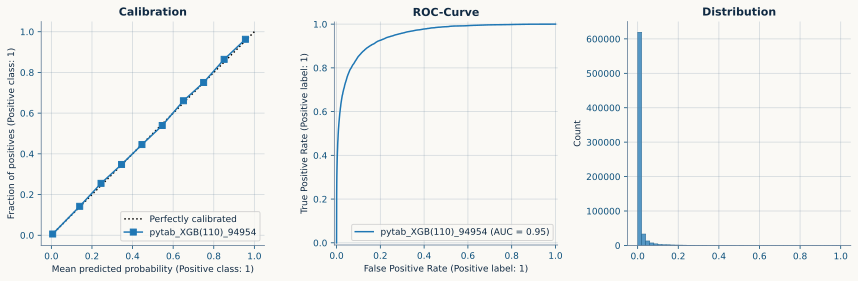

In [42]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12, 4)) 
CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout()
plt.show()

print()

In [26]:
# !rm -r /kaggle/working